# NYC Commuting Analysis
Alireza Shirkhodaee (ar.shirkhodaee@gmail.com)

## Description
   This script analyzes commuting flows between neighborhoods (tracts) of New
   York City. Specifically, it:
     1. Produces a summary statistics table for tract-to-tract variables
     2. Creates a county-to-county commuting dataset and displays it
     3. Generates a binned scatterplot with log(distance) on the x-axis and
        log(commuters) on the y-axis
     4. Reports estimates from three gravity-model regressions

## Usage
- This code is written in Python and can be executed in Google Colab or locally.
- Google Colab is recommended because all required libraries can be installed
     easily via pip. If running locally, ensure all libraries in 'Requirements'
     are installed.
- Colab link: https://colab.research.google.com/drive/14w0kvylNAy5p2aApdTvbRsVuoZT7VB1z?usp=sharing

## Requirements
   - Python version 3.10.12 or above
   - To install the dependencies in Colab, run:
       `pip install binsreg linearmodels stargazer requests`
   - If not using Colab, make sure you have:
       pandas, numpy, matplotlib, statsmodels, zipfile, requests, io,
       scipy, binsreg, linearmodels, geopandas,
       folium, stargazer, and plotly

## Included Files
   - All necessary files are fetched online; an active internet connection
     is required. No additional local files need to be loaded.


# Install required packages

In [1]:
!pip install binsreg linearmodels stargazer requests > /dev/null 2>&1 #silent installation
print("Required libraries are installed.")

Required libraries are installed.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import zipfile
import requests
from io import BytesIO
from scipy.stats import linregress
import binsreg
import linearmodels.panel as panel
from linearmodels.panel import compare
import geopandas as gpd
import folium
from folium.plugins import MarkerCluster
from folium.plugins import AntPath
from stargazer.stargazer import Stargazer
import plotly.express as px
import plotly.graph_objects as go
import warnings

warnings.filterwarnings('ignore')

# Project paths: the notebook lives in <project>/code and every path is relative to the project root
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'code' else Path.cwd()
DATA_DIR = ROOT / 'data'
OUTPUT_DIR = ROOT / 'output'
TABLE_DIR = OUTPUT_DIR / 'tables'
FIG_DIR = OUTPUT_DIR / 'figures'
for d in (DATA_DIR, TABLE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Download the data

In [3]:
# Download and Unzip Data
url = 'http://www.jdingel.com/temp/nyc_commuting_tracts.csv.zip'
zip_file = DATA_DIR / 'nyc_commuting_tracts.csv.zip'
csv_file = DATA_DIR / 'nyc_commuting_tracts.csv'

# Download the ZIP file from the URL
response = requests.get(url)
if response.status_code == 200:
    with open(zip_file, 'wb') as f:
        f.write(response.content)
else:
    raise Exception("Failed to download file.")

# Extract the ZIP file
with zipfile.ZipFile(zip_file, 'r') as z:
    z.extractall(DATA_DIR)

# Load the data into a DataFrame
data = pd.read_csv(csv_file)

# Display the first few rows of the data
data.head()


,home_tract,work_tract,commuters,physical_distance,traveltime_public,traveltime_car
0,36005000200,36005000200,4,0.000000,0,0.0
1,36005000200,36005001600,4,1.588514,21,4.0
2,36005000200,36005001900,7,4.449193,81,14.0
3,36005000200,36005002000,1,1.641288,14,5.0
4,36005000200,36005002800,2,2.687694,28,7.0


# Summary Statistics

## Summary Statistics Table

In [4]:
# Summary Statistics Table
summary_stats = data.drop(columns=['home_tract', 'work_tract']).describe(percentiles=[0.25, 0.5, 0.75]).transpose()
summary_stats = summary_stats[['count', 'mean', 'std', '25%', '50%', '75%']]
summary_stats['count'] = summary_stats['count'].apply(lambda x: "%d" % x)
summary_stats.iloc[:, 1:] = summary_stats.iloc[:, 1:].applymap(lambda x: "%.3f" % x)

print(summary_stats)
# Escape underscore, and percent sign
summary_stats.index = summary_stats.index.str.replace(r'([%_])', r'\\\1', regex=True)
summary_stats.columns = summary_stats.columns.str.replace('%', '\%', regex=False)

# Export to LaTeX
latex_code = summary_stats.to_latex(
    index=True,
    caption="Summary Statistics",
    label="tab:summary_stats",
)

# Save to file
with open(TABLE_DIR / 'summary_stats.tex', 'w') as f:
    f.write(latex_code)

print("Summary statistics exported to LaTeX file successfully.")


                    count    mean     std     25%     50%     75%
commuters          689550   3.658   8.183   1.000   1.000   3.000
physical_distance  689550  10.935   7.072   5.436   9.837  15.246
traveltime_public  689550  55.980  27.829  36.000  53.000  72.000
traveltime_car     689550  20.245   9.927  13.000  19.000  27.000
Summary statistics exported to LaTeX file successfully.


##  The 15-minute city
Compute the fraction of commuters with travel time of 15 minutes or less

In [5]:
data['fastest_time'] = data[['traveltime_public', 'traveltime_car']].min(axis=1)
fraction_15_minute_commuters = (data['fastest_time'] <= 15).sum() / len(data)
print(f"Fraction of commuters with <= 15 min commute: {fraction_15_minute_commuters:.2%}")

Fraction of commuters with <= 15 min commute: 34.82%


## County-to-County Aggregation

In [6]:
data['home_county'] = data['home_tract'].astype(str).str[:5]
data['work_county'] = data['work_tract'].astype(str).str[:5]
county_commutes = data.groupby(['home_county', 'work_county'])['commuters'].sum().reset_index()
county_commutes.to_csv(OUTPUT_DIR / 'nyc_commuting_counties.csv', index=False)

In [7]:
county_commutes.head()

,home_county,work_county,commuters
0,36005,36005,101825
1,36005,36047,46547
2,36005,36061,182139
3,36005,36081,30706
4,36005,36085,2011


In [8]:
# Function to replace FIPS codes with county names
def replace_fips_with_name(df, home_col='home_county', work_col='work_county'):
    # Fetch FIPS to county name mapping from an online source
    url = 'https://raw.githubusercontent.com/kjhealy/fips-codes/master/state_and_county_fips_master.csv'
    fips_data = pd.read_csv(url)

    # Create a mapping from FIPS to county name
    fips_to_name = fips_data.set_index('fips')['name'].to_dict()

    def fips_to_county_name(fips):
        return fips_to_name.get(fips, 'Unknown')

    # Ensure columns are numeric
    df[home_col] = pd.to_numeric(df[home_col], errors='coerce')
    df[work_col] = pd.to_numeric(df[work_col], errors='coerce')

    # Apply to both columns
    df[home_col] = df[home_col].apply(fips_to_county_name)
    df[work_col] = df[work_col].apply(fips_to_county_name)
    return df


county_commutes = replace_fips_with_name(county_commutes)
print(county_commutes.head())


    home_county      work_county  commuters
0  Bronx County     Bronx County     101825
1  Bronx County     Kings County      46547
2  Bronx County  New York County     182139
3  Bronx County    Queens County      30706
4  Bronx County  Richmond County       2011


In [9]:
def plot_sankey(df):
  # Create node labels for home and work
  home_nodes = [f"{county} (home)" for county in df['home_county'].unique().tolist()]
  work_nodes = [f"{county} (work)" for county in df['home_county'].unique().tolist()]

  nodes = home_nodes + work_nodes

  # Create source and target indices for Sankey diagram
  source = df['home_county'].apply(lambda x: nodes.index(f"{x} (home)")).tolist()
  target = df['work_county'].apply(lambda x: nodes.index(f"{x} (work)")).tolist()

  # Create Sankey diagram
  fig = go.Figure(data=[go.Sankey(
      node=dict(
          pad=15,
          thickness=20,
          line=dict(color='black', width=0.5),
          label=nodes
      ),
      link=dict(
          source=source,
          target=target,
          value=df['commuters']
      )
  )])

  fig.update_layout(
      title_text='County Commuting Patterns',
      font_size=12,
      width=800,
      height=600
  )
  fig.show()

plot_sankey(county_commutes)


In [10]:
# Pivot your DataFrame to get a matrix
pivot_df = county_commutes.pivot(
    index='home_county',
    columns='work_county',
    values='commuters'
).fillna(0)

# Create a heatmap using Plotly
fig = px.imshow(
    pivot_df,
    labels=dict(
        x="Work County",
        y="Home County",
        color="Commuters"
    ),
    x=pivot_df.columns,
    y=pivot_df.index,
    color_continuous_scale='Blues',
    text_auto=True
)

# Update the layout for title, size, and axis label styling
fig.update_layout(
    title="Commuters Heatmap by County",
    width=800,
    height=600,
)

# Adjust the x-axis and y-axis tick label rotation
fig.update_xaxes(tickangle=-45, tickfont=dict(size=10))
fig.update_yaxes(tickangle=0, tickfont=dict(size=10))

# Show the figure
fig.show()


In [11]:
pivot_df

work_county,Bronx County,Kings County,New York County,Queens County,Richmond County
home_county,,,,,
Bronx County,101825,46547,182139,30706,2011
Kings County,15348,338966,404756,69313,9106
New York County,21187,47570,491351,25208,2095
Queens County,16763,100120,281972,181237,3076
Richmond County,2128,40015,58457,6305,44234


# Regressions

## Binned Scatterplot

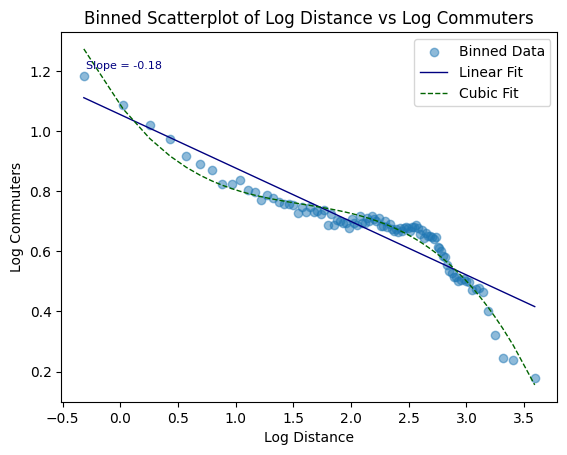

In [12]:
# Binned Scatterplot
data['log_distance'] = np.log(data['physical_distance'])
data['log_commuters'] = np.log(data['commuters'])

bins = pd.qcut(data['physical_distance'], 100, duplicates='drop')
binned_data = data.groupby(bins).agg({'log_distance': 'mean', 'log_commuters': 'mean'}).reset_index(drop=True)
binned_data.replace([np.inf, -np.inf], np.nan, inplace=True)
binned_data.dropna(inplace=True)

plt.scatter(
    binned_data['log_distance'],
    binned_data['log_commuters'],
    alpha=0.5,
    label='Binned Data'  # Add legend label for data points
)

# Linear Fit
slope, intercept, _, _, _ = linregress(binned_data['log_distance'], binned_data['log_commuters'])
plt.plot(
    binned_data['log_distance'],
    intercept + slope * binned_data['log_distance'],
    color='navy',
    linewidth=1,
    label='Linear Fit'
)

# Annotate the slope
plt.annotate(
    f"Slope = {slope:.2f}",      # Text to display
    xy=(0.05, 0.9),             # Position in Axes coordinates (0=left/bottom, 1=right/top)
    xycoords='axes fraction',   # Interpret (x,y) as a fraction of the Axes
    fontsize=8,
    color='navy'
)

# Polynomial (Cubic) Fit
coeffs = np.polyfit(binned_data['log_distance'], binned_data['log_commuters'], 3)
cubic_fit = np.poly1d(coeffs)
plt.plot(
    binned_data['log_distance'],
    cubic_fit(binned_data['log_distance']),
    color='darkgreen',
    linestyle='--',
    linewidth=1,
    label='Cubic Fit'
)

plt.xlabel('Log Distance')
plt.ylabel('Log Commuters')
plt.title('Binned Scatterplot of Log Distance vs Log Commuters')
plt.legend()
plt.savefig(FIG_DIR / 'binscatter.png')
plt.show()


### Using Predefined Libraries to Plot Binscatter

<ggplot: (640 x 480)>


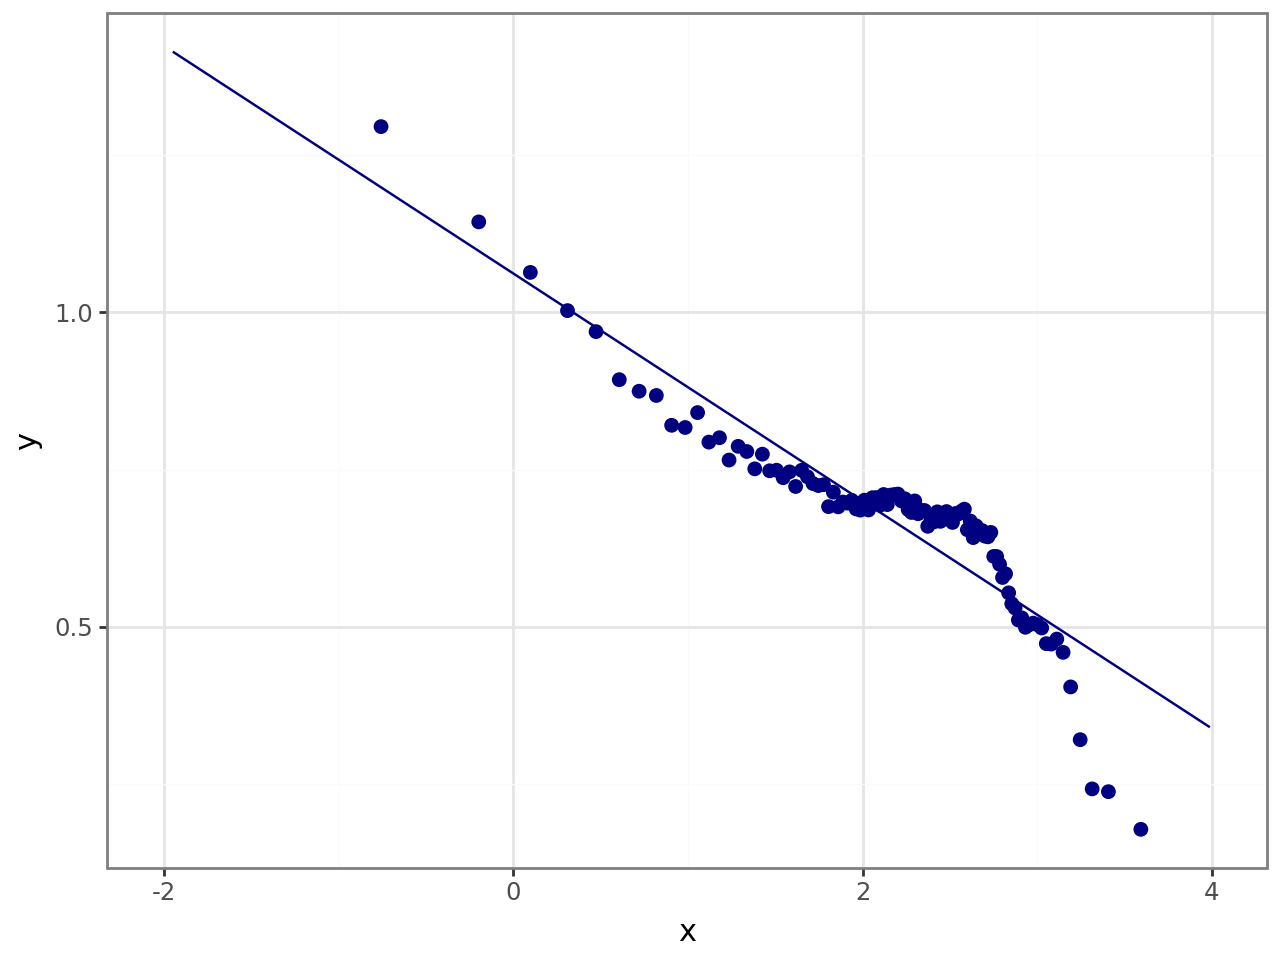

In [13]:
# Use binsreg to create a non-parametric binned scatterplot
data_fe = data.copy()
data_fe.replace([np.inf, -np.inf], np.nan, inplace=True)
data_fe.dropna(inplace=True)
est = binsreg.binsreg(data_fe['log_commuters'], data_fe['log_distance'], nbins=100, polyreg=1)
est.bins_plot.show()


## Regression Analysis

In [14]:
# Data Preparation for Regression
data_fe['log_traveltime_public'] = np.log(data_fe['traveltime_public'])
data_fe['log_traveltime_car'] = np.log(data_fe['traveltime_car'])

# Regress log commuters on log travel time by public transit
data_fe = data_fe.set_index(['home_tract', 'work_tract'])
X1 = data_fe[['log_traveltime_public']]
y = data_fe['log_commuters']
model1 = panel.PooledOLS(y, sm.add_constant(X1)).fit()

# 2. Fixed effects regression with home and work tract
model2 = panel.PanelOLS(y, sm.add_constant(X1), entity_effects=True).fit()

# 3. Add log travel time by car and fixed effects
X3 = data_fe[['log_traveltime_public', 'log_traveltime_car']]
model3 = panel.PanelOLS(y, sm.add_constant(X3), entity_effects=True).fit()

# Use Stargazer to generate LaTeX tables
stargazer = Stargazer([model1, model2, model3])
stargazer.title('Regression Results')
stargazer.custom_columns(['Model 1', 'Model 2', 'Model 3'], [1, 1, 1])
stargazer.significance_levels([0.1, 0.05, 0.01])
stargazer.show_degrees_of_freedom(False)
stargazer.covariate_order(['log_traveltime_public', 'log_traveltime_car'])
stargazer.add_line('home_tract FE', ['No', 'Yes', 'Yes'])
stargazer.add_line('work_tract FE', ['No', 'Yes', 'Yes'])
stargazer.add_custom_notes(["Standard errors are in parentheses."])


latex_output = stargazer.render_latex()

# Save to a .tex file
with open(TABLE_DIR / "regression_results.tex", "w") as f:
    f.write(latex_output)

stargazer


# Geographical chart (optional)

In [15]:
def fips_to_latlon(fips_codes):
    # Load USA counties shapefile from Census Bureau
    shapefile_url = "https://www2.census.gov/geo/tiger/TIGER2022/COUNTY/tl_2022_us_county.zip"

    # Read shapefile using geopandas
    counties = gpd.read_file(shapefile_url)

    # Convert FIPS code to a number
    counties['GEOID'] = pd.to_numeric(counties['GEOID'], errors='coerce')

    # Filter for the given FIPS codes
    filtered = counties[counties['GEOID'].isin(fips_codes)]

    # Calculate centroid of each polygon
    filtered['centroid'] = filtered.geometry.centroid

    # Extract lat/lon from centroid
    filtered['latitude'] = filtered['centroid'].y
    filtered['longitude'] = filtered['centroid'].x

    # Return DataFrame of results
    results = filtered[['GEOID', 'latitude', 'longitude']]
    return results

In [16]:
# Read data
county_commutes = pd.read_csv(OUTPUT_DIR / 'nyc_commuting_counties.csv')
geo_df = fips_to_latlon(county_commutes["home_county"])

# Merge to get home coordinates
commutes_with_home = county_commutes.merge(
    geo_df.rename(columns={'GEOID': 'home_county', 'latitude': 'home_lat', 'longitude': 'home_lon'}),
    on='home_county',
    how='left'
)

# Merge to get work coordinates
commutes_full = commutes_with_home.merge(
    geo_df.rename(columns={'GEOID': 'work_county', 'latitude': 'work_lat', 'longitude': 'work_lon'}),
    on='work_county',
    how='left'
)

# Center the map around NYC
nyc_coordinates = [40.7128, -74.0060]
nyc_map = folium.Map(location=nyc_coordinates, zoom_start=11)

# Iterate over each row to plot the commuter flow
for idx, row in commutes_full.iterrows():
    home_location = (row['home_lat'], row['home_lon'])
    work_location = (row['work_lat'], row['work_lon'])

    # Scale the line weight; adjust the divisor as needed for better visualization
    line_weight = max(row['commuters'] / 10000, 1)  # Ensure a minimum weight of 1

    AntPath(
        locations=[home_location, work_location],
        color='blue',
        weight=line_weight,
        opacity=0.6,
        dash_array='10, 20',
        delay=300
    ).add_to(nyc_map)

# Save the map to an HTML file
output_map_file = str(FIG_DIR / "nyc_commute_flow.html")
nyc_map.save(output_map_file)
print(f"Map has been saved to {output_map_file}")

# Display the map in a Jupyter notebook
try:
    from IPython.display import display
    display(nyc_map)
except ImportError:
    pass  # Not in a Jupyter environment

Map has been saved to nyc_commute_flow.html
